# S1.9 · Trial cleaning

This notebook audits trial cleaning on one session from the configured IBL release. Run it with the Stage 0 Python environment. The first run may download trial data into `data/raw`.

The counts start with the table returned by IBL. Any trials truncated upstream are outside the audit.

## Plan

1. Load the configuration and one session's trials from IBL.
2. Clean the trials with the project rules and record how many are removed at each step.
3. Compare the reaction time distribution before and after cleaning.
4. Check the project exclusions against the official IBL mask, and check the choice-direction convention.
5. Show the output columns of the clean table.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "config.yaml").is_file())
sys.path.insert(0, str(root))

from src.common.settings import connect_ibl, load_config
from src.data.clean_trials import clean_trials, load_trials

SESSION_ID = "6713a4a7-faed-4df2-acab-ee4e63326f8d"
config = load_config()
trials, official_mask = load_trials(connect_ibl(), SESSION_ID, config)
cleaned, report = clean_trials(trials, official_mask, config)
print(f"Session: {SESSION_ID}")

Session: 6713a4a7-faed-4df2-acab-ee4e63326f8d


## Trial counts

The audit assigns each exclusion to the first applicable rule. The official IBL mask determines which trials are retained.

In [2]:
summary = pd.DataFrame({
    "Before cleaning": [report["n_input_trials"]],
    "After cleaning": [report["n_kept_trials"]],
    "Excluded": [report["n_removed_trials"]],
})
display(summary)
steps = pd.DataFrame(report["steps"]).set_index("step")
display(steps.rename(columns={
    "n_before": "Before", "n_removed": "Excluded", "n_after": "After",
}))

,Before cleaning,After cleaning,Excluded
0,565,394,171


,Before,Excluded,After
step,,,
no_choice,565,9,556
missing_required_events,556,28,528
reaction_time_out_of_range,528,134,394
other IBL rules,394,0,394


## Reaction time before and after cleaning

Reaction time is the interval from stimulus onset to first movement. Both histograms use the same bins. The plot shows the range around the configured limits and reports how many input values fall outside the displayed range or lack a finite reaction time. The cleaning limits include both endpoints.

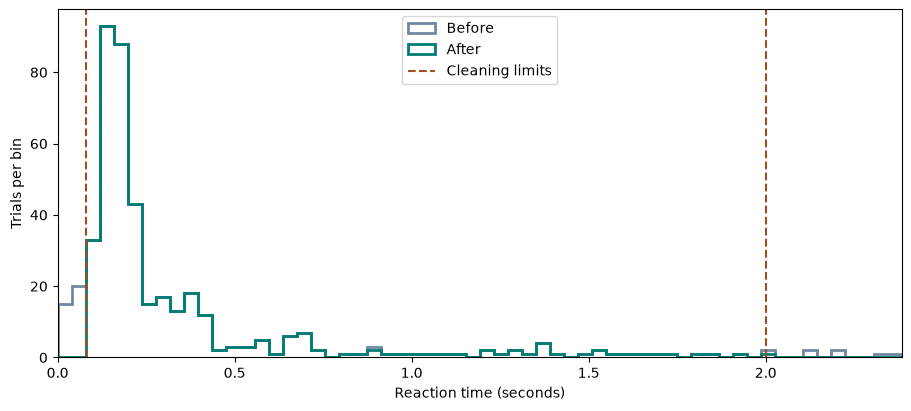

Input trials outside plot range: 95
Input trials without a finite reaction time: 33


In [3]:
before = trials["firstMovement_times"] - trials["stimOn_times"]
after = cleaned["reaction_time"]
limits = report["reaction_time_limits"]
lower, upper = limits["min"], limits["max"]
plot_min = min(0, lower)
plot_max = upper + max(0.1, 0.2 * (upper - lower))
bins = np.linspace(plot_min, plot_max, 61)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for values, label, color in [(before, "Before", "#7186a0"),
                             (after, "After", "#007c72")]:
    ax.hist(values.dropna(), bins=bins, histtype="step", linewidth=2,
            label=label, color=color)
ax.axvline(lower, color="#a34c20", linestyle="--", label="Cleaning limits")
ax.axvline(upper, color="#a34c20", linestyle="--")
ax.set(xlim=(plot_min, plot_max), xlabel="Reaction time (seconds)",
       ylabel="Trials per bin")
ax.legend()
plt.show()

finite = np.isfinite(before)
outside = finite & ~before.between(plot_min, plot_max)
print(f"Input trials outside plot range: {outside.sum()}")
print(f"Input trials without a finite reaction time: {(~finite).sum()}")

## Validation and output columns

The IBL check compares the project exclusions with the official mask. The choice-direction check uses retained trials with nonzero contrast and reports the coding convention alongside the raw sign-agreement rate. Zero-contrast trials can still be retained for later analysis.

In [4]:
ibl = report["ibl_check"]
direction = report["choice_direction"]
print(f"IBL mask check: {'PASS' if ibl['passed'] else 'FAIL'}")
print(f"Additional exclusions by IBL: {ibl['n_extra_ibl_rejections']}")
print(f"Choice direction: {direction['convention']}")
print(f"Sign agreement: {direction['agreement_fraction']:.1%} "
      f"across {direction['n_trials_checked']} nonzero-contrast trials")

display(cleaned[["trial_number", "y", "stim_side", "contrast", "is_error",
                 "is_zero_contrast", "reaction_time"]].head())

IBL mask check: PASS
Additional exclusions by IBL: 0
Choice direction: same
Sign agreement: 100.0% across 360 nonzero-contrast trials


,trial_number,y,stim_side,contrast,is_error,is_zero_contrast,reaction_time
0,9,1,1,0.125,False,False,0.146144
1,12,1,-1,-0.250,True,False,0.861355
2,14,1,-1,-0.250,True,False,1.841254
3,16,1,1,0.250,False,False,0.104318
4,19,1,-1,-0.125,True,False,1.392827


## Conclusions

- The three cleaning steps run in order, and each excluded trial is counted once only.
- The project rules never remove a trial that the official IBL mask keeps; any disagreement stops the run with an error.
- Reaction times outside the configured limits are the largest source of exclusions.
- The choice-direction convention matches the project assumption on the nonzero-contrast trials.
- This run verifies the cleaning workflow on one session. The team-wide Stage 1 audit covers the final session list.